# Ciber-Inmunología Swarm en Google Colab

Este notebook corre el proyecto completo en Colab usando su GPU. Los nodos son simulados, así que toda la federación ocurre acá; al final quedan en tu Google Drive los resultados (CSV y PNG) y los pesos de los modelos (`.pt`).

**Antes de empezar:** activá la GPU en el menú **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**.

No hace falta subir nada: el dataset CIC-IDS2017 se descarga solo a tu Drive la primera vez.

Ejecutá las celdas en orden.

## 1. Comprobar la GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Descargar el código

In [2]:
import os

%cd /content
if not os.path.exists("ciber-inmunologia"):
    !git clone -q https://github.com/xeviercr4/ciber-inmunologia.git
%cd /content/ciber-inmunologia
!git pull -q

/content
/content/ciber-inmunologia


## 3. Conectar Google Drive y obtener el dataset

Colab va a pedir permiso para acceder a tu Drive. Ahí se crea la carpeta `ciber-inmunologia` con dos subcarpetas:

- `raw`: los 8 CSV de CIC-IDS2017. **La primera vez se descargan solos** (unos 885 MB, tarda unos minutos); en las sesiones siguientes se toman de Drive.
- `resultados`: lo que generan los experimentos. Se guarda directo en Drive, así no se pierde si la sesión se corta.

Los CSV se bajan de una copia pública en Hugging Face. La fuente oficial es el [Canadian Institute for Cybersecurity](https://www.unb.ca/cic/datasets/ids-2017.html), que pide completar un formulario; si preferís esa, subí vos los 8 CSV a `ciber-inmunologia/raw` y esta celda usará los tuyos.

In [3]:
import shutil
from google.colab import drive

drive.mount("/content/drive")

CARPETA_DRIVE = "/content/drive/MyDrive/ciber-inmunologia"
os.makedirs(f"{CARPETA_DRIVE}/raw", exist_ok=True)
os.makedirs(f"{CARPETA_DRIVE}/resultados", exist_ok=True)
os.makedirs("data/raw", exist_ok=True)

# Los experimentos leen esta variable y guardan sus resultados en Drive
os.environ["CIBER_RESULTADOS"] = f"{CARPETA_DRIVE}/resultados"

ORIGEN = "https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main"
DIAS = [
    "Monday-WorkingHours",
    "Tuesday-WorkingHours",
    "Wednesday-workingHours",
    "Thursday-WorkingHours-Morning-WebAttacks",
    "Thursday-WorkingHours-Afternoon-Infilteration",
    "Friday-WorkingHours-Morning",
    "Friday-WorkingHours-Afternoon-PortScan",
    "Friday-WorkingHours-Afternoon-DDos",
]

for dia in DIAS:
    nombre = f"{dia}.pcap_ISCX.csv"
    en_drive = f"{CARPETA_DRIVE}/raw/{nombre}"
    en_colab = f"data/raw/{nombre}"
    if os.path.exists(en_colab):
        continue
    if os.path.exists(en_drive):
        print(f"Desde Drive:  {nombre}")
        shutil.copy(en_drive, en_colab)      # leer del disco de Colab es mucho más rápido que de Drive
    else:
        print(f"Descargando:  {nombre}")
        !wget -q -O "{en_colab}" "{ORIGEN}/{nombre}"
        shutil.copy(en_colab, en_drive)      # copia permanente en Drive

print()
!ls -lh data/raw

Mounted at /content/drive
Desde Drive:  Monday-WorkingHours.pcap_ISCX.csv
Desde Drive:  Tuesday-WorkingHours.pcap_ISCX.csv
Desde Drive:  Wednesday-workingHours.pcap_ISCX.csv
Desde Drive:  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Desde Drive:  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Desde Drive:  Friday-WorkingHours-Morning.pcap_ISCX.csv
Desde Drive:  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Desde Drive:  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

total 844M
-rw------- 1 root root  74M Nov 18 00:41 Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
-rw------- 1 root root  74M Nov 18 00:41 Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
-rw------- 1 root root  56M Nov 18 00:41 Friday-WorkingHours-Morning.pcap_ISCX.csv
-rw------- 1 root root 169M Nov 18 00:41 Monday-WorkingHours.pcap_ISCX.csv
-rw------- 1 root root  80M Nov 18 00:41 Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
-rw------- 1 root root  50M Nov 18 00:41 T

## 4. Instalar Flower y verificar el entorno

Al instalar, pip muestra en rojo una lista larga de "dependency conflicts" (protobuf, click, cryptography). **Es esperable y no es un error del proyecto:** Flower necesita versiones más viejas de esas librerías que otros paquetes preinstalados en Colab (TensorFlow, wandb, Google Cloud), que acá no se usan.

Lo importante es que al final diga `Dispositivo: cuda` y `Entorno verificado correctamente`.

In [4]:
!pip install -q -r requirements-colab.txt
!python verificar_entorno.py

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
bigframes 2.51.0 requires rich<14,>=12.4.4, but you have rich 14.3.4 which is incompatible.
Python 3.13.16
  torch        2.14.1+cu130
  numpy        2.4.6
  sklearn      1.6.1
  pandas       2.2.3
  pyarrow      23.0.1
  matplotlib   3.10.0
  yaml         6.0.3
  flwr         1.43.0
  ray          2.55.1
Dispositivo: cuda
Operación de prueba en cuda: OK  (CUDA disponible: True, MPS disponible: False)
Entorno verificado correctamente.


## 5. Preprocesar los datos

`MUESTRA` es la fracción del tráfico benigno que se usa; los ataques se conservan todos, para no perder las familias raras (Web y Bot). Empezá con `0.1` (10%) para medir tiempos y subila después.

In [5]:
MUESTRA = 0.1
!python -m src.preprocess --sample $MUESTRA

Leyendo CSV de /content/ciber-inmunologia/data/raw ...
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 225,745 filas
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 286,467 filas
  Friday-WorkingHours-Morning.pcap_ISCX.csv: 191,033 filas
  Monday-WorkingHours.pcap_ISCX.csv: 529,918 filas
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 288,602 filas
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 170,366 filas
  Tuesday-WorkingHours.pcap_ISCX.csv: 445,909 filas
  Wednesday-workingHours.pcap_ISCX.csv: 692,703 filas
Limpiando ...
  Filas iniciales:                 2,830,743
  Sin inf/NaN:                     2,827,876
  Sin etiquetas fuera de familia:  2,827,829  (descartadas: ['Infiltration', 'Heartbleed'])
  Sin duplicados:                  2,520,751
  Columnas constantes eliminadas: 8  -> quedan 69 características
  Muestra del 10%:                    252,074

Listo (CIC-IDS2017). 69 características.
  Familia          train      test
  Benign      

## 6. Experimentos

Elegí el modelo (`mlp` es rápido; `transformer` es el modelo principal y tarda más) y la cantidad de rondas. Cada experimento guarda su CSV y su gráfica en Drive al terminar.

Ejecutá un experimento por vez: no se pueden correr dos simulaciones al mismo tiempo.

In [8]:
MODELO = "mlp"
RONDAS = 5

In [9]:
# E1 — centralizado vs. aislado vs. federado
!python -m experiments.e1_comparacion --modelo $MODELO --rondas $RONDAS

I0000 00:00:1794962983.550066    3410 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794962986.077816    3410 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E1 | modelo mlp | reparto dirichlet | 5 rondas
  nodo      Benign        DoS       DDoS   PortScan BruteForce        Web        Bot      TOTAL
     0      47,050        787      7,069      1,522        249         24         31     56,732
     1      74,875      2,567      1,579        116         34          3          0     79,174
     2         519      1,780         46        355        121         57          4      2,882
     3      44,201      6,102      1,343      1,319        195         37        121     53,318
     4         960      4,263        204      

In [10]:
# E2 — FedAvg vs. FedProx vs. cabezas locales, con alpha = 0.1, 0.5 y 1.0
!python -m experiments.e2_heterogeneidad --modelo $MODELO --rondas $RONDAS

I0000 00:00:1794963141.177042    4482 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794963143.775206    4482 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E2 | modelo mlp | 5 rondas

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
  alpha 0.1 | FedAvg                           F1 global 0.691 | F1 local 0.729

      

In [ ]:
# E3 — zero-day simulado: una corrida por familia y, al final, una figura que las compara.
# Cada familia es un entrenamiento federado completo: para ir más rápido, dejá menos familias en la lista.
FAMILIAS_E3 = ["DoS", "DDoS", "PortScan", "BruteForce", "Web", "Bot"]
for familia in FAMILIAS_E3:
    !python -m experiments.e3_zero_day --modelo $MODELO --rondas $RONDAS --familia $familia
!python -m experiments.e3_resumen --modelo $MODELO

In [12]:
# E4 — 1 a 3 nodos maliciosos: FedAvg vs. Krum vs. mediana
!python -m experiments.e4_maliciosos --modelo $MODELO --rondas $RONDAS

I0000 00:00:1794963991.182366   11821 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794963993.628888   11821 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E4 | modelo mlp | 10 nodos | 5 rondas

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
  FedAvg sin atacantes         F1 macro 0.709 | falsos positivos 0.002

    

## 7. Ver las gráficas

e1_mlp.png


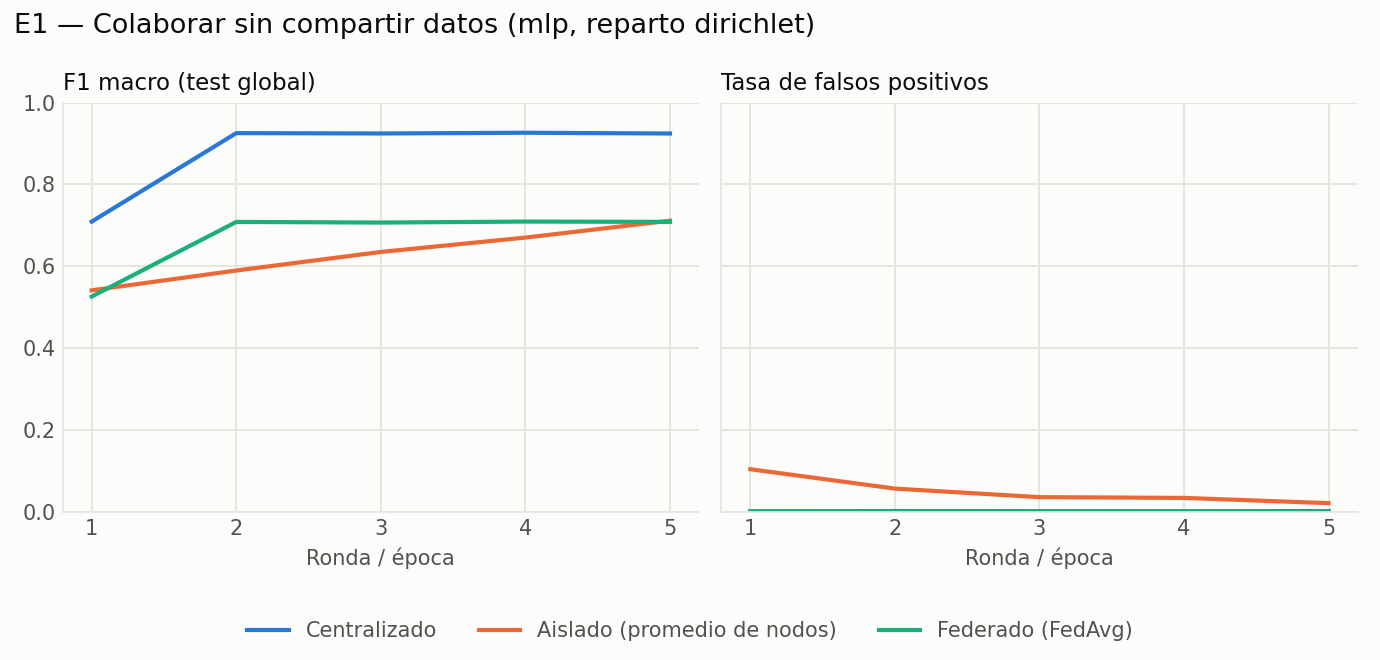

e2_mlp.png


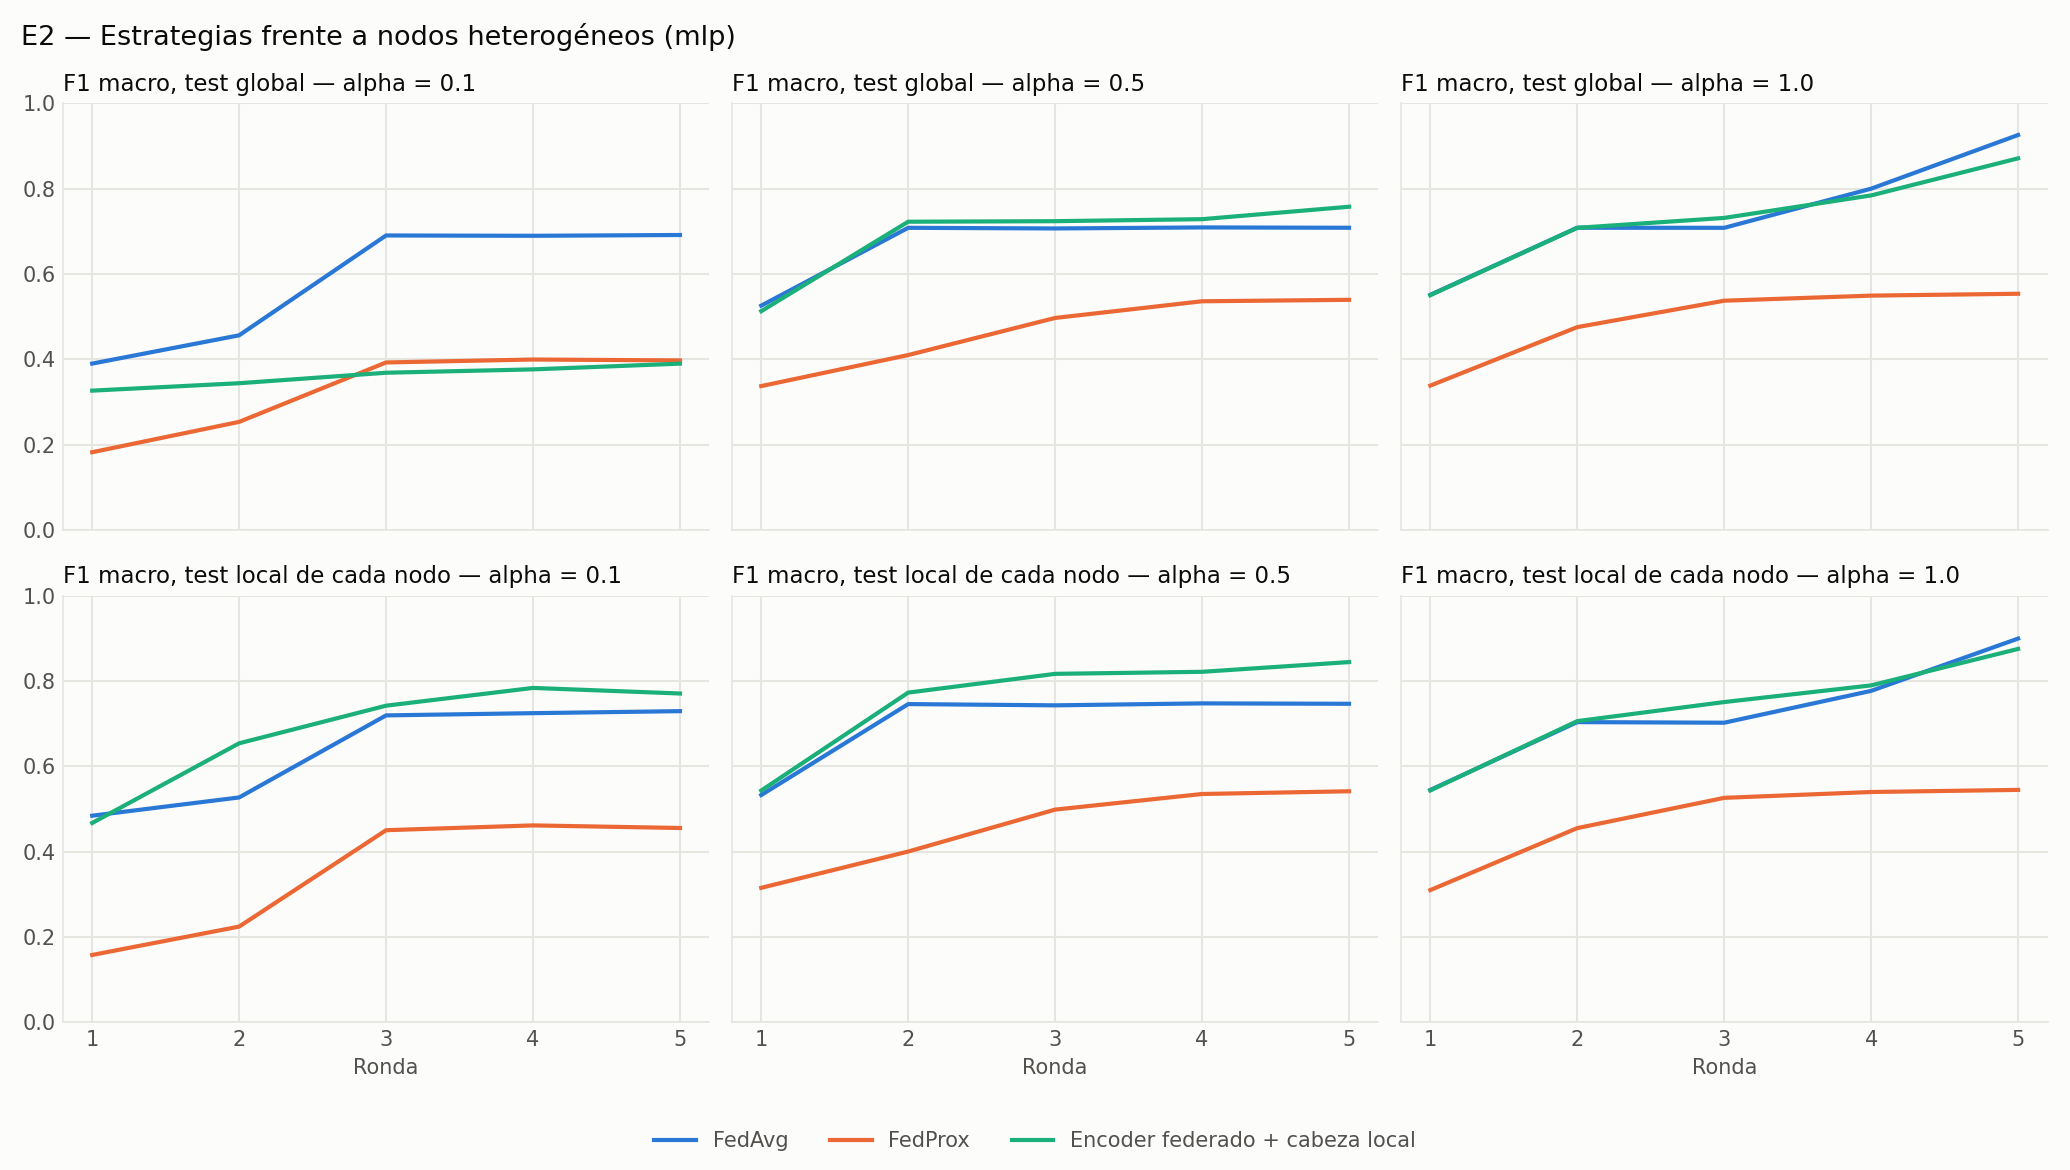

e3_mlp_DDoS.png


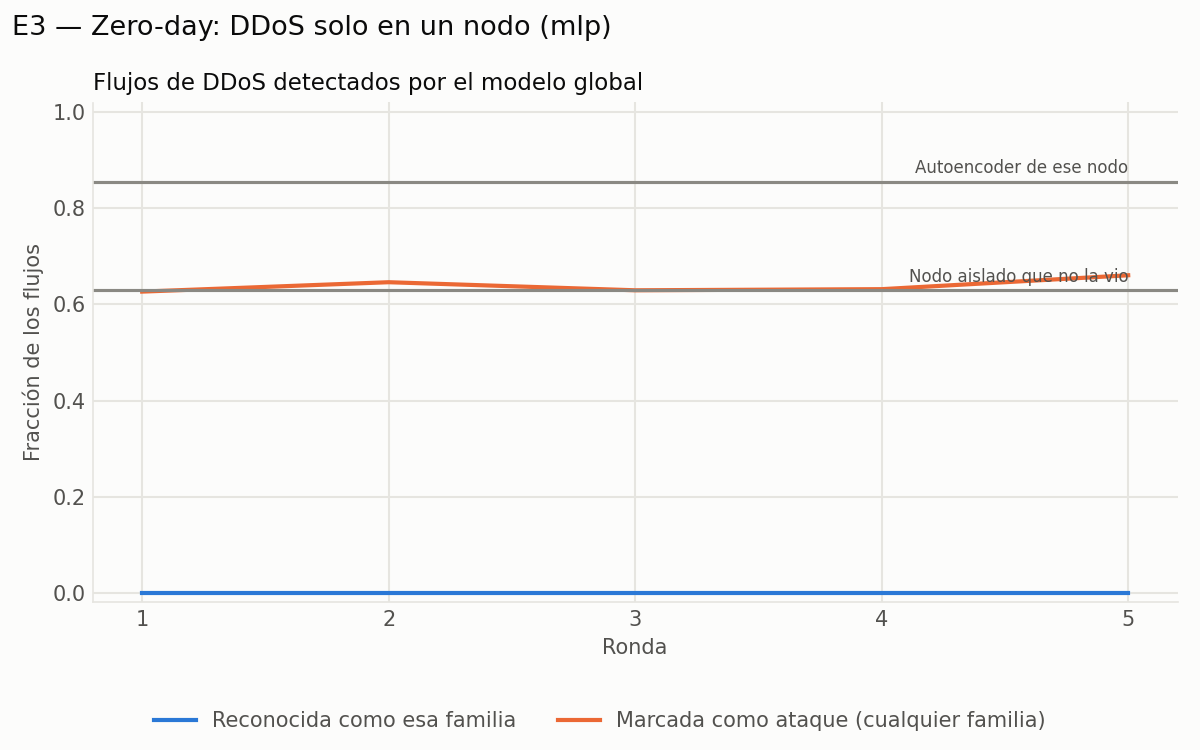

e4_mlp.png


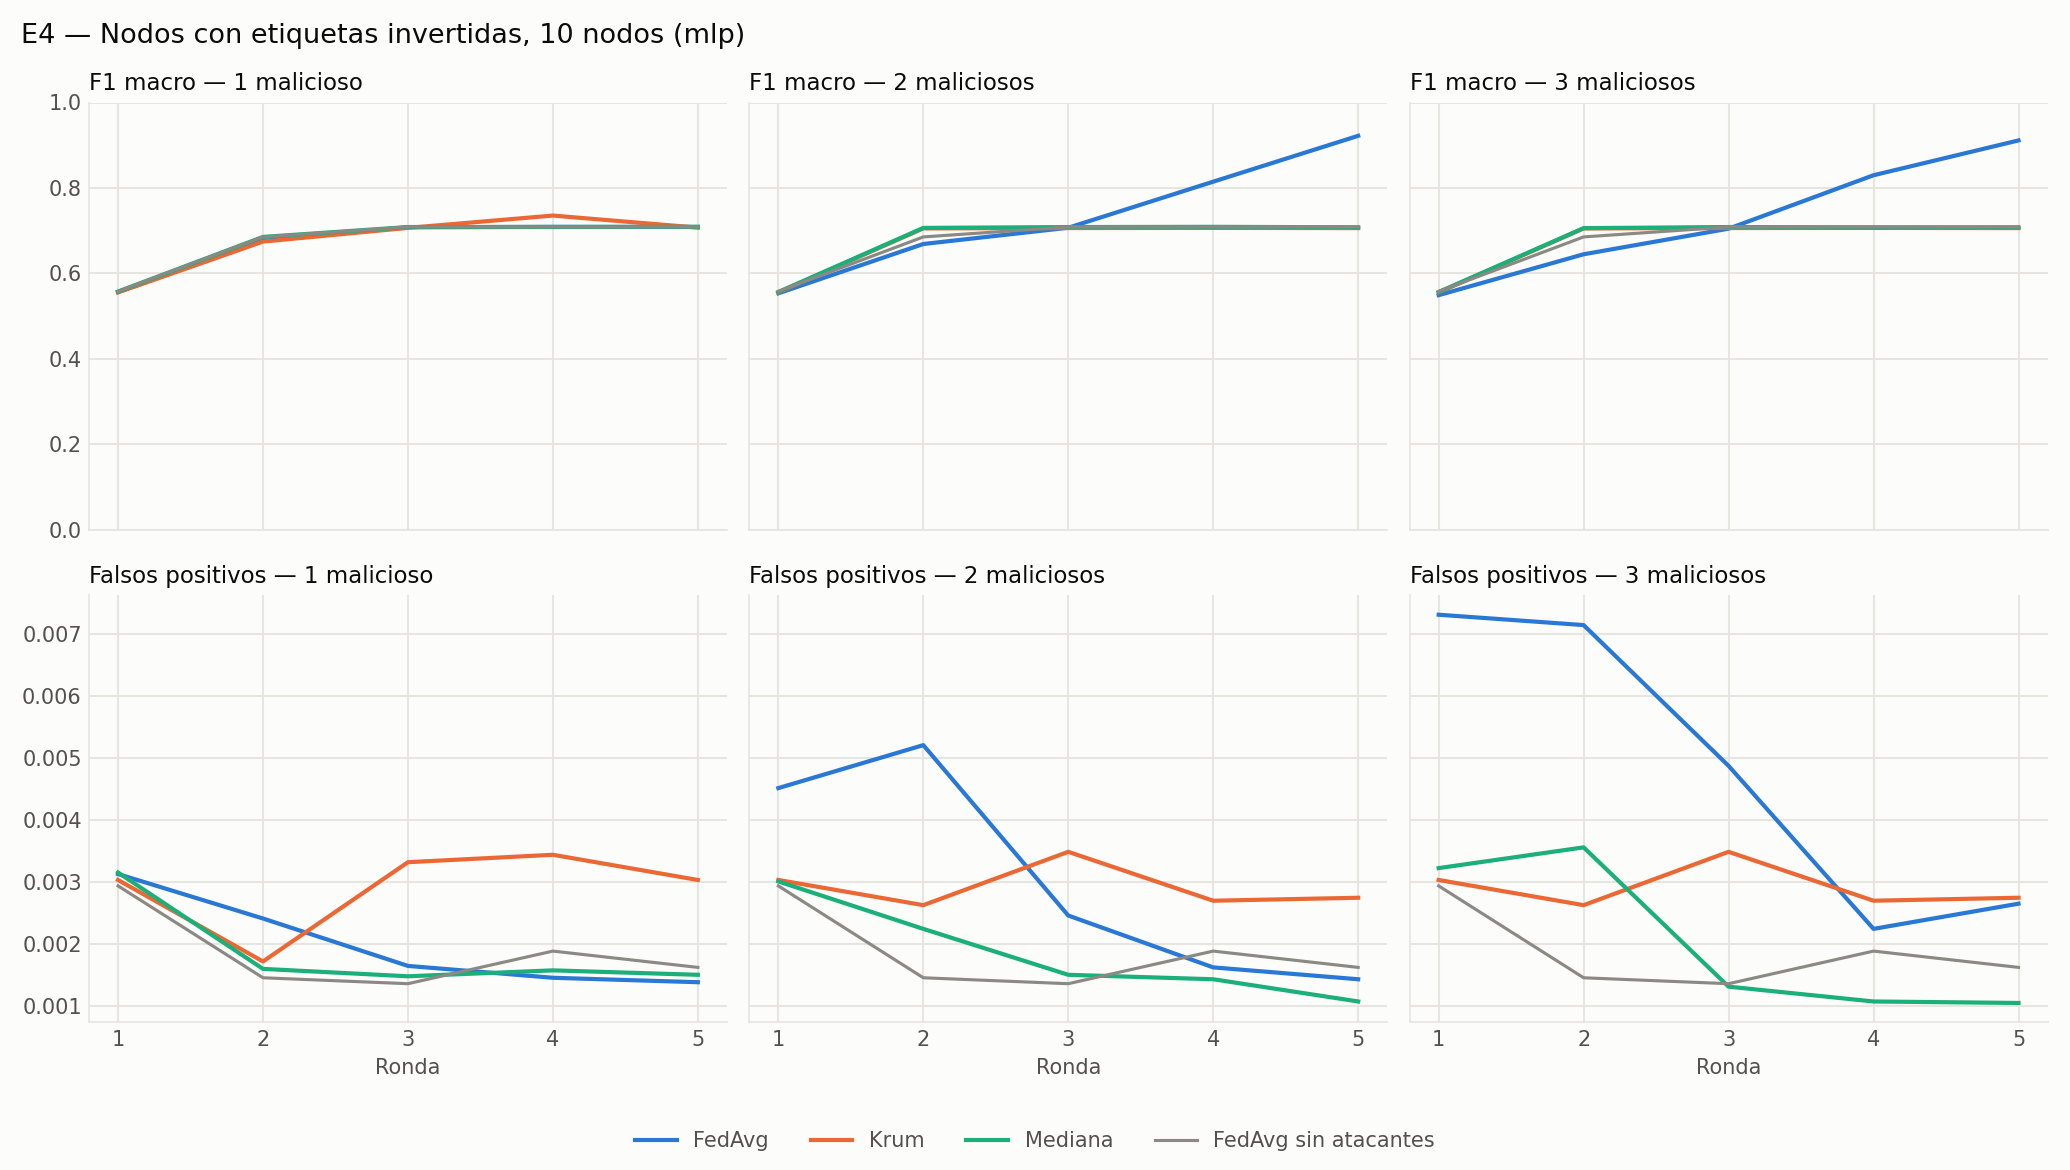

In [13]:
import glob
from IPython.display import Image, display

for ruta in sorted(glob.glob(f"{CARPETA_DRIVE}/resultados/*.png")):
    print(os.path.basename(ruta))
    display(Image(ruta, width=900))

## 8. Llevar los resultados a tu computadora

Todo quedó en tu Drive, en `ciber-inmunologia/resultados` (los pesos de los modelos están en la subcarpeta `modelos`). Esta celda además arma un zip y lo descarga.

Para evaluar en tu máquina un modelo entrenado acá, copiá el `.pt` y ejecutá:

```
python -m src.centralized --evaluar ruta/al/archivo.pt
```

Importante: tu máquina tiene que haber preprocesado los mismos datos con la misma muestra (`--sample`) que se usó acá, porque el modelo depende de las columnas y de la normalización.

In [ ]:
import zipfile
from google.colab import files

# Solo se incluyen los archivos generados por el proyecto. Si abriste un CSV con
# Google Sheets, Drive crea un acceso directo (.gsheet) que no se puede copiar.
EXTENSIONES = (".csv", ".png", ".pt")
origen = f"{CARPETA_DRIVE}/resultados"
with zipfile.ZipFile("/content/resultados.zip", "w", zipfile.ZIP_DEFLATED) as archivo_zip:
    for carpeta, _, nombres in os.walk(origen):
        for nombre in sorted(nombres):
            if nombre.endswith(EXTENSIONES):
                ruta = os.path.join(carpeta, nombre)
                archivo_zip.write(ruta, os.path.relpath(ruta, origen))
    print(f"Archivos en el zip: {len(archivo_zip.namelist())}")
files.download("/content/resultados.zip")